# 01 — Analyse Exploratoire des Données (EDA)
**Objectif** : Distribution des classes, dimensions, intensités, déséquilibre.
Aucune dépendance PyTorch ici — pure analyse avec PIL / NumPy / Matplotlib.


In [1]:
import os, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
import pandas as pd
import warnings; warnings.filterwarnings('ignore')

TRAIN_DIR = '../../data/chest_xray/train'
VAL_DIR   = '../../data/chest_xray/val'
TEST_DIR  = '../../data/chest_xray/test'
CLASSES   = ['NORMAL', 'BACTERIA', 'VIRUS']
COLORS    = ['#2ecc71', '#e74c3c', '#3498db']


In [2]:
# ── Décompte par split / classe ───────────────────────────────
print(f"{'Split':8s}  {'NORMAL':>8}  {'BACTERIA':>10}  {'VIRUS':>7}  {'Total':>7}")
print("─" * 50)
totals = {}
for split, path in [('Train', TRAIN_DIR), ('Val', VAL_DIR), ('Test', TEST_DIR)]:
    counts = {cls: len(os.listdir(os.path.join(path, cls)))
              if os.path.exists(os.path.join(path, cls)) else 0
              for cls in CLASSES}
    totals[split] = counts
    total = sum(counts.values())
    print(f"{split:8s}  {counts['NORMAL']:>8}  {counts['BACTERIA']:>10}  {counts['VIRUS']:>7}  {total:>7}")


Split       NORMAL    BACTERIA    VIRUS    Total
──────────────────────────────────────────────────
Train         1341           0        0     1341
Val              8           0        0        8
Test           234           0        0      234


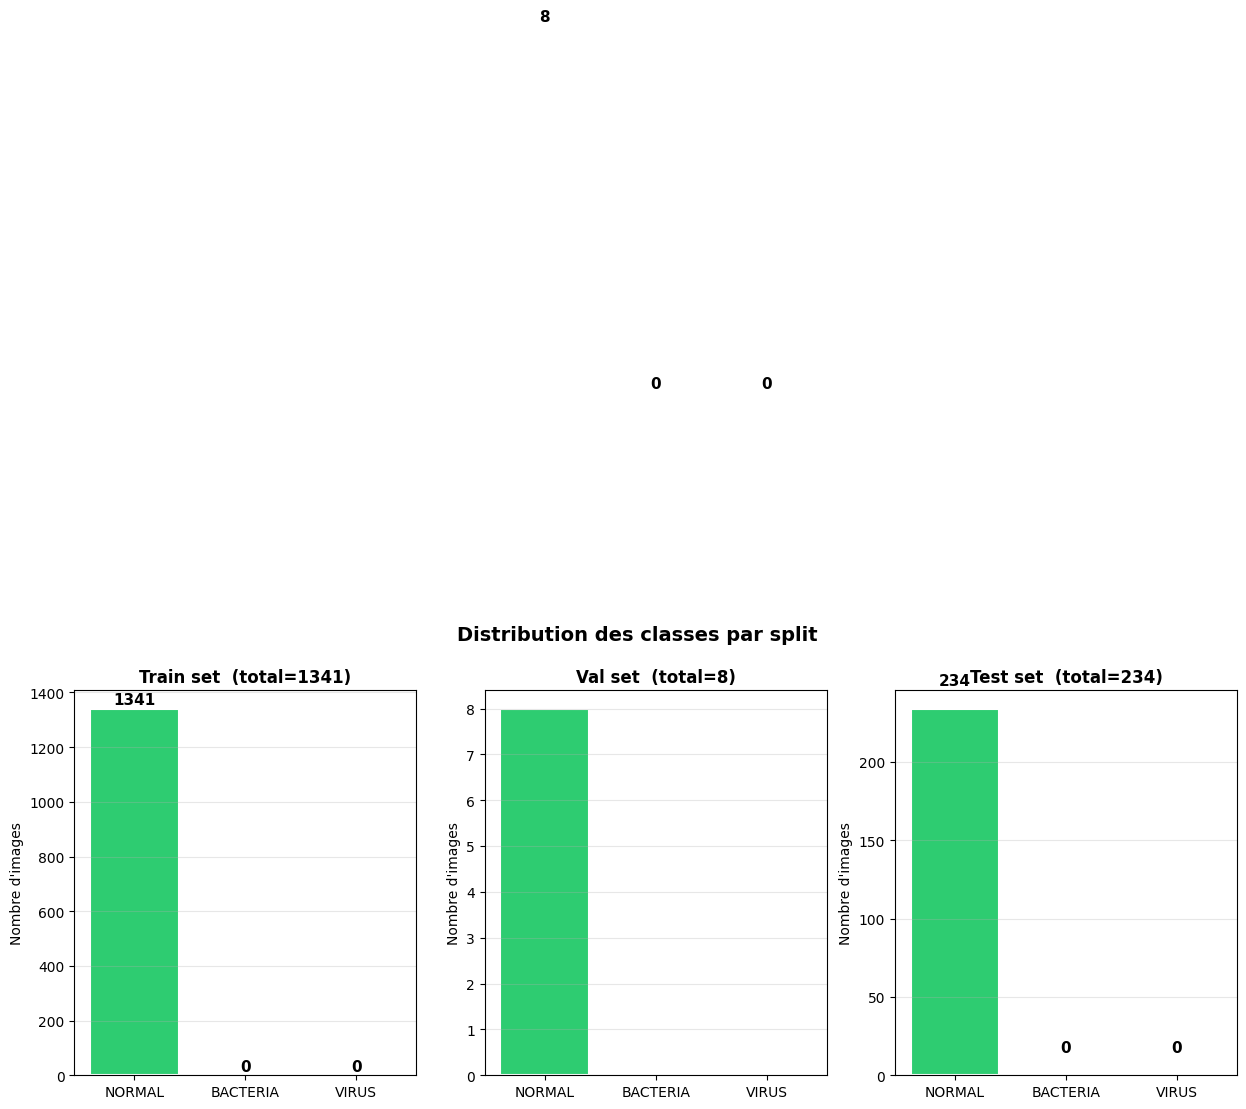

In [3]:
# ── Distribution barplot ─────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (split, counts) in zip(axes, totals.items()):
    bars = ax.bar(CLASSES, counts.values(), color=COLORS, edgecolor='white', linewidth=1.5)
    ax.set_title(f'{split} set  (total={sum(counts.values())})', fontsize=12, fontweight='bold')
    ax.set_ylabel("Nombre d'images"); ax.grid(axis='y', alpha=0.3)
    for bar, val in zip(bars, counts.values()):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 15,
                str(val), ha='center', fontsize=11, fontweight='bold')
plt.suptitle("Distribution des classes par split", fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout(); plt.show()


FileNotFoundError: [WinError 3] Le chemin d’accès spécifié est introuvable: '../../data/chest_xray/train\\BACTERIA'

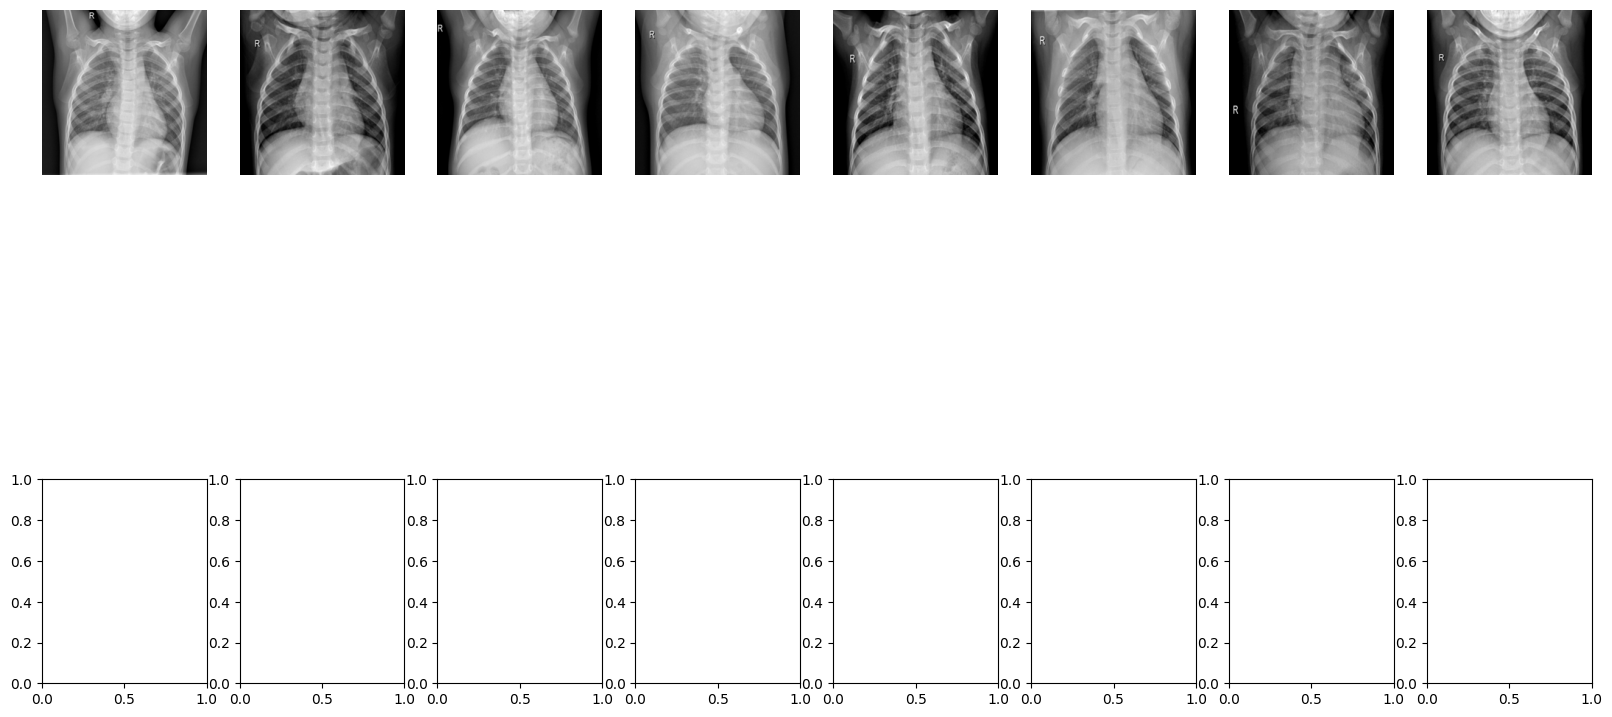

In [4]:
# ── Exemples par classe ───────────────────────────────────────
fig, axes = plt.subplots(3, 8, figsize=(20, 9))
for row, (cls, color) in enumerate(zip(CLASSES, COLORS)):
    cls_path = os.path.join(TRAIN_DIR, cls)
    if not os.path.exists(cls_path):
        for ax in axes[row]: ax.axis('off'); continue
    for col, fname in enumerate(os.listdir(cls_path)[:8]):
        img = Image.open(os.path.join(cls_path, fname)).convert('RGB').resize((224, 224))
        axes[row, col].imshow(img, cmap='gray'); axes[row, col].axis('off')
        if col == 0:
            axes[row, col].set_ylabel(cls, fontsize=11, color=color,
                                       fontweight='bold', rotation=90, labelpad=10)
plt.suptitle('Exemples de radiographies par classe', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()


In [ ]:
# ── Dimensions originales ─────────────────────────────────────
dims = []
for cls in CLASSES:
    cls_path = os.path.join(TRAIN_DIR, cls)
    if not os.path.exists(cls_path): continue
    for fname in os.listdir(cls_path)[:80]:
        try:
            w, h = Image.open(os.path.join(cls_path, fname)).size
            dims.append({'Classe': cls, 'Largeur': w, 'Hauteur': h, 'Ratio': w/h})
        except: pass
df = pd.DataFrame(dims)
print(df.groupby('Classe')[['Largeur','Hauteur','Ratio']].describe().round(1).to_string())
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for cls, color in zip(CLASSES, COLORS):
    sub = df[df['Classe'] == cls]
    axes[0].scatter(sub['Largeur'], sub['Hauteur'], alpha=0.4, color=color, label=cls, s=15)
    axes[1].hist(sub['Ratio'], bins=25, alpha=0.55, color=color, label=cls)
axes[0].set_xlabel('Largeur (px)'); axes[0].set_ylabel('Hauteur (px)')
axes[0].set_title('Dimensions des images', fontsize=11); axes[0].legend()
axes[1].set_xlabel('Ratio L/H'); axes[1].set_title('Distribution des ratios', fontsize=11)
axes[1].legend(); plt.tight_layout(); plt.show()
print("→ Dimensions très variables → resize à 224×224 pour ResNet50 (standard ImageNet)")


In [ ]:
# ── Intensité moyenne par classe ──────────────────────────────
intensities = {cls: [] for cls in CLASSES}
for cls in CLASSES:
    cls_path = os.path.join(TRAIN_DIR, cls)
    if not os.path.exists(cls_path): continue
    for fname in os.listdir(cls_path)[:120]:
        try:
            arr = np.array(Image.open(os.path.join(cls_path, fname)).convert('L').resize((64,64)))
            intensities[cls].append(arr.mean())
        except: pass
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for cls, color in zip(CLASSES, COLORS):
    axes[0].hist(intensities[cls], bins=30, alpha=0.6, color=color, label=cls, density=True)
axes[0].set_xlabel('Intensité moyenne'); axes[0].set_ylabel('Densité')
axes[0].set_title('Distribution des intensités par classe', fontsize=11); axes[0].legend(); axes[0].grid(alpha=0.3)
data_bp = [intensities[cls] for cls in CLASSES]
bp = axes[1].boxplot(data_bp, labels=CLASSES, patch_artist=True)
for patch, color in zip(bp['boxes'], COLORS):
    patch.set_facecolor(color); patch.set_alpha(0.7)
axes[1].set_title('Boxplot des intensités', fontsize=11); axes[1].grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()
print("OBSERVATION: BACTERIA/VIRUS → images plus sombres (opacités pulmonaires)")


## Conclusions EDA
| Observation | Impact |
|---|---|
| Déséquilibre BACTERIA (×2) | `weight=compute_class_weights()` dans CrossEntropyLoss |
| Dimensions variables 512–2048px | `transforms.Resize(224)` dans le pipeline |
| Intensités plus faibles en pneumonie | Signal appris naturellement par les Conv |
| Qualité bonne | Pas de débruitage nécessaire |
